<a href="https://colab.research.google.com/github/pajola/secai-course/blob/main/module-02-data-security/02_representation_and_bias.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab" width="150"></a>

# 2 · Representation and bias audit — a balanced label is not a balanced population

**SecAI course · Data Security for AI, part 2**

Notebook 1 asked *who is in the data*. This one asks *how the data treats them*. A loan model learns from past decisions; if those decisions were unfair,
or if some people are barely present, the model inherits the problem at scale, and in the EU a credit-scoring system is a **high-risk AI system**
(AI Act, Annex III) that must use data "examined in view of possible biases" (Art. 10).

There is no external attacker here: the risk is built into the data.

| | Bias risk |
|---|---|
| **Harm** | the model approves or rejects people differently because of a protected attribute (gender, age), or is unreliable for groups it rarely saw |
| **Sources** | **historical bias** in the labels (past human decisions), **representation bias** (who was sampled), **proxies** (features that encode the protected attribute) |
| **Who needs to act** | the reviewer: measure before training, set a fairness gate before deployment, document what can't be fixed |

**Open-source tool used here:** [Fairlearn](https://fairlearn.org) (Microsoft): per-group metrics and fairness-constrained training. Each metric is first computed by hand.

In [1]:
# Setup — on Google Colab, fetch the dataset generator and install the open-source tools used below.
import os, sys, subprocess, urllib.request
if "google.colab" in sys.modules:
    if not os.path.exists("northvale.py"):
        urllib.request.urlretrieve(
            "https://raw.githubusercontent.com/pajola/secai-course/main/module-02-data-security/northvale.py", "northvale.py")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "faker", "fairlearn"], check=True)

In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from northvale import load, REF_DATE

df, _ = load()
age = ((REF_DATE - pd.to_datetime(df.date_of_birth)).dt.days // 365.25).astype(int)
df["age_band"] = pd.cut(age, [0, 30, 40, 50, 60, 200], right=False, labels=["<30", "30-39", "40-49", "50-59", "60+"])
df[["gender", "age_band", "postcode", "annual_income_eur", "credit_score", "loan_amount_eur", "approved"]].head()

,gender,age_band,postcode,annual_income_eur,credit_score,loan_amount_eur,approved
0,M,50-59,35136,10300.0,618,4500.0,0
1,F,40-49,35135,25700.0,714,18500.0,0
2,M,50-59,35121,31100.0,601,18000.0,0
3,F,<30,35124,40800.0,678,24500.0,0
4,M,50-59,35121,31000.0,779,8500.0,1


## 2.1 Label balance vs population balance

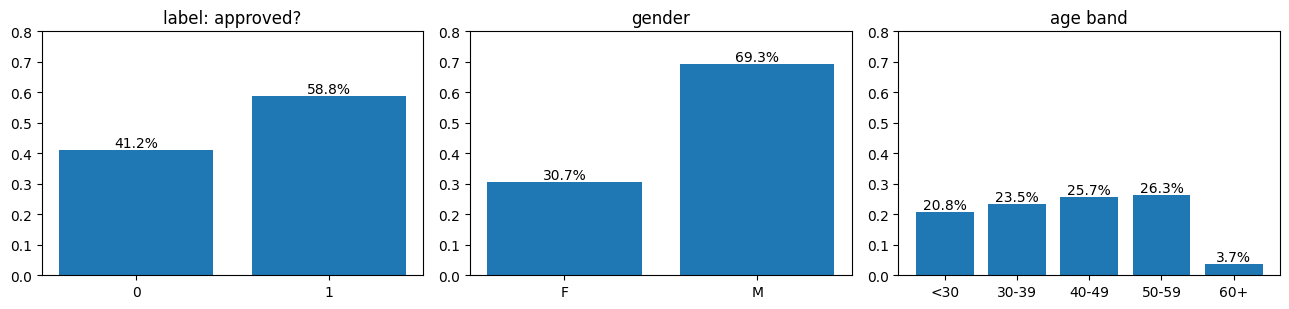

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.2))
for a, col, title in zip(ax, ["approved", "gender", "age_band"], ["label: approved?", "gender", "age band"]):
    share = df[col].value_counts(normalize=True, sort=False).sort_index()
    a.bar(share.index.astype(str), share.values, color="tab:blue")
    for x, v in zip(share.index.astype(str), share.values): a.text(x, v + 0.01, f"{v:.1%}", ha="center")
    a.set_title(title); a.set_ylim(0, 0.8)
plt.tight_layout(); plt.show()

* **Label:** 58.8% approved / 41.2% rejected. Acceptable; no rebalancing needed.
* **Gender:** 69.3% men / 30.7% women. Representation bias: the model sees more than twice as many men.
* **Age:** applicants aged 60+ are **3.7%** of the data, 44 people.

Why do 44 rows matter? Any number measured on a small group is noisy. The 95% confidence interval (Wilson) of the approval rate per age band:

In [4]:
def wilson(k, n, z=1.96):
    p = k / n; d = 1 + z**2 / n
    c = (p + z**2 / (2 * n)) / d; h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d
    return c - h, c + h

t = df.groupby("age_band", observed=True).approved.agg(n="size", approved="sum")
t["rate"] = t.approved / t.n
t["95% CI"] = [f"{lo:.0%} – {hi:.0%}" for lo, hi in (wilson(k, n) for k, n in zip(t.approved, t.n))]
t.style.format({"rate": "{:.1%}"})

,n,approved,rate,95% CI
age_band,,,,
<30,250,145,58.0%,52% – 64%
30-39,282,172,61.0%,55% – 67%
40-49,308,175,56.8%,51% – 62%
50-59,316,186,58.9%,53% – 64%
60+,44,28,63.6%,49% – 76%


For the 60+ band the interval is more than twice as wide as for the others: whatever the model does for this group, we can't measure it reliably,
and it has seen too few examples to learn it well. A balanced label tells you nothing about this.

## 2.2 Bias audit on the labels

**Disparate impact (DI) ratio** = approval rate of the unprivileged group / approval rate of the privileged group.
The US EEOC **four-fifths rule** treats DI < 0.80 as evidence of adverse impact. It is a heuristic, not a law of nature, but a widely used review threshold.

In [5]:
rate = df.groupby("gender").approved.mean()
di = rate["F"] / rate["M"]
print(f"approval rate  men: {rate['M']:.1%}   women: {rate['F']:.1%}")
print(f"disparate impact ratio F/M = {di:.2f}  ->  {'FLAG: below 0.80' if di < 0.8 else 'ok'}")

approval rate  men: 64.3%   women: 46.5%
disparate impact ratio F/M = 0.72  ->  FLAG: below 0.80


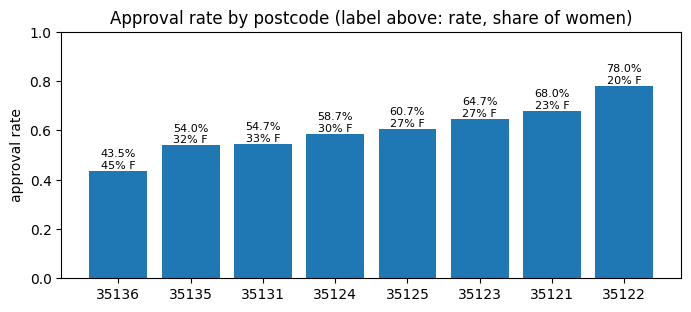

spread: 43.5% (35136) to 78.0% (35122)


In [6]:
by_pc = df.groupby("postcode").agg(rate=("approved", "mean"), women=("gender", lambda g: (g == "F").mean()),
                                   income=("annual_income_eur", "median")).sort_values("rate")
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.bar(by_pc.index, by_pc.rate, color="tab:blue")
for x, (r, w) in zip(by_pc.index, zip(by_pc.rate, by_pc.women)): ax.text(x, r + 0.01, f"{r:.1%}\n{w:.0%} F", ha="center", fontsize=8)
ax.set_ylim(0, 1); ax.set_ylabel("approval rate"); ax.set_title("Approval rate by postcode (label above: rate, share of women)")
plt.show()
print(f"spread: {by_pc.rate.min():.1%} ({by_pc.index[0]}) to {by_pc.rate.max():.1%} ({by_pc.index[-1]})")

Postcode approval rates range from 43.5% (35136) to 78.0% (35122). The lowest-approval postcode is also the one with the most women (45%) and the lowest income.

### The same audit with Fairlearn

`MetricFrame` computes any metric per group; `demographic_parity_ratio` is the DI ratio. Here `y_pred` is the historical label: we audit the **past decisions** themselves.

In [7]:
from fairlearn.metrics import MetricFrame, selection_rate, demographic_parity_ratio

mf = MetricFrame(metrics={"selection rate": selection_rate, "count": lambda y, p: len(y)},
                 y_true=df.approved, y_pred=df.approved, sensitive_features=df.gender)
print(mf.by_group)
print("\ndemographic parity ratio:", round(demographic_parity_ratio(df.approved, df.approved, sensitive_features=df.gender), 2))

        selection rate  count
gender                       
F             0.464674  368.0
M             0.643029  832.0

demographic parity ratio: 0.72


Is the gap explained by merit? Compare men and women **with the same credit score**:

In [8]:
df["score_band"] = pd.qcut(df.credit_score, 4, labels=["Q1 (lowest)", "Q2", "Q3", "Q4 (highest)"])
same_merit = df.pivot_table(index="score_band", columns="gender", values="approved", aggfunc="mean", observed=True)
same_merit["gap (M - F)"] = same_merit.M - same_merit.F
same_merit.style.format("{:.1%}")

gender,F,M,gap (M - F)
score_band,,,
Q1 (lowest),16.2%,29.1%,12.9%
Q2,29.9%,46.2%,16.3%
Q3,59.2%,79.5%,20.3%
Q4 (highest),94.0%,97.7%,3.6%


In every credit-score quartile, women were approved less often than men. Part of the overall gap comes from lower incomes (a pay gap, itself a bias upstream),
but the decisions differ even at equal scores: the labels encode **historical bias**. A model trained to reproduce them learns to reproduce the bias.

## 2.3 "Just drop the gender column": fairness through unawareness

The intuitive fix: don't give the model the protected attribute. We train a logistic regression **without gender** and measure its decisions on a held-out test set.

In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

def features(d, postcode=True):
    X = pd.DataFrame({"log_income": np.log(d.annual_income_eur), "credit_score": d.credit_score,
                      "loan_to_income": d.loan_amount_eur / d.annual_income_eur,
                      "age": ((REF_DATE - pd.to_datetime(d.date_of_birth)).dt.days // 365.25)})
    if postcode: X = X.join(pd.get_dummies(d.postcode, prefix="pc", dtype=float))
    return X

X = features(df)
mu, sd = X.mean(), X.std()
X = (X - mu) / sd
idx_tr, idx_te = train_test_split(df.index, test_size=0.3, stratify=df.approved, random_state=0)
y, g = df.approved, df.gender

def report(name, pred, idx=idx_te):
    r = pd.Series(pred, index=idx).groupby(g[idx]).mean()
    return {"model": name, "accuracy": (pred == y[idx]).mean(), "approval M": r["M"], "approval F": r["F"], "DI F/M": r["F"] / r["M"]}

results = []
blind = LogisticRegression(max_iter=2000).fit(X.loc[idx_tr], y[idx_tr])
results.append(report("no gender column", blind.predict(X.loc[idx_te])))
pd.DataFrame(results).set_index("model").style.format("{:.3f}")

,accuracy,approval M,approval F,DI F/M
model,,,,
no gender column,0.825,0.663,0.509,0.768


The model never saw gender, yet its DI is still below 0.80. Two reasons:

1. **The labels are biased.** The model is trained to predict past decisions, and past decisions treated women worse.
2. **Proxies.** Other features carry the gender information. How well can a model guess an applicant's gender **without** the gender column?

In [10]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import roc_auc_score

female = (g == "F").astype(int)
for name, cols in [("postcode only", [c for c in X if c.startswith("pc_")]),
                   ("postcode + income", ["log_income"] + [c for c in X if c.startswith("pc_")]),
                   ("all model features", list(X))]:
    p = cross_val_predict(LogisticRegression(max_iter=2000), X[cols], female, cv=5, method="predict_proba")[:, 1]
    print(f"proxy detector, {name:20s}: AUC = {roc_auc_score(female, p):.3f}   (0.5 = no information)")

proxy detector, postcode only       : AUC = 0.575   (0.5 = no information)
proxy detector, postcode + income   : AUC = 0.640   (0.5 = no information)
proxy detector, all model features  : AUC = 0.632   (0.5 = no information)


The features predict gender better than chance (AUC 0.5). The proxy is weak for any one person, but systematic across 1,200 people,
and systematic is what a model exploits. Removing a column removes a name, not the information.

This is how **Amazon's recruiting tool** failed (Reuters, 2018): trained on ten years of mostly male hires, it learned to penalise words such as "women's"
(as in "women's chess club") without ever being given the applicant's gender.

## 2.4 Mitigation 1 — reweighing (by hand)

Kamiran & Calders (2012): give each training example a weight so that, **in the weighted data, gender and label are independent**.
For a group *g* and label *y*: `w(g, y) = P(g) · P(y) / P(g, y)`. Approved women (under-represented relative to independence) weigh more,
approved men less. Gender is used **only to compute the weights**, from the separate audit table; it is never a feature.

In [11]:
tr = pd.DataFrame({"g": g[idx_tr], "y": y[idx_tr]})
p_g, p_y, p_gy = tr.g.value_counts(normalize=True), tr.y.value_counts(normalize=True), tr.value_counts(normalize=True)
weights = tr.apply(lambda r: p_g[r.g] * p_y[r.y] / p_gy[(r.g, r.y)], axis=1)
print(tr.assign(w=weights).groupby(["g", "y"]).w.first().round(2).unstack().rename(columns={0: "rejected", 1: "approved"}))

reweighed = LogisticRegression(max_iter=2000).fit(X.loc[idx_tr], y[idx_tr], sample_weight=weights)
results.append(report("reweighing", reweighed.predict(X.loc[idx_te])))
pd.DataFrame(results).set_index("model").style.format("{:.3f}")

y  rejected  approved
g                    
F      0.76      1.28
M      1.15      0.91


,accuracy,approval M,approval F,DI F/M
model,,,,
no gender column,0.825,0.663,0.509,0.768
reweighing,0.828,0.667,0.509,0.763


Almost no change. Reweighing tells the model "approved women matter more", but the model has no gender column and only weak proxies,
so it has no way to tell which applicants are women: the extra weight spreads over everyone with similar features. Pre-processing fixes
like this work when the model has a path to the group; here the bias sits in information the model can't see.

## 2.5 Mitigation 2 — a fairness constraint with Fairlearn

`ExponentiatedGradient` (Agarwal et al., 2018) trains a classifier subject to a constraint, here **demographic parity** with a ratio bound of 0.8:
exactly the four-fifths rule we are auditing against. It needs the sensitive feature at training time only, not at prediction time.

In [12]:
from fairlearn.reductions import ExponentiatedGradient, DemographicParity

eg = ExponentiatedGradient(LogisticRegression(max_iter=2000), constraints=DemographicParity(ratio_bound=0.8))
eg.fit(X.loc[idx_tr], y[idx_tr], sensitive_features=g[idx_tr])
np.random.seed(0)                                   # the result is a randomised classifier
results.append(report("Fairlearn: parity constraint (training)", eg.predict(X.loc[idx_te])))

from fairlearn.postprocessing import ThresholdOptimizer
to = ThresholdOptimizer(estimator=LogisticRegression(max_iter=2000), constraints="demographic_parity", predict_method="predict_proba")
to.fit(X.loc[idx_tr], y[idx_tr], sensitive_features=g[idx_tr])
results.append(report("Fairlearn: per-group thresholds", to.predict(X.loc[idx_te], sensitive_features=g[idx_te], random_state=0)))
pd.DataFrame(results).set_index("model").style.format("{:.3f}")

,accuracy,approval M,approval F,DI F/M
model,,,,
no gender column,0.825,0.663,0.509,0.768
reweighing,0.828,0.667,0.509,0.763
Fairlearn: parity constraint (training),0.800,0.703,0.570,0.811
Fairlearn: per-group thresholds,0.811,0.581,0.605,1.041


The constrained model passes the four-fifths rule at a cost of a few points of accuracy. `ThresholdOptimizer` reaches parity with less accuracy loss,
but look at how it works: it applies **different approval thresholds to men and women**, so it needs the applicant's gender **at decision time**.
That is explicit different treatment by gender; for credit decisions in the EU it is legally very hard to defend. A technically better number can be the wrong choice.

Now read the accuracy column carefully: it is measured **against the historical labels**,
the same labels we just showed to be biased. Part of the "lost" accuracy is the model refusing to copy the past. Neither metric can tell you what the
*right* decision was; that needs a policy choice (which fairness definition, which threshold) and, ideally, better labels.

What mitigation can't fix: **under-representation**. Per-age-band accuracy of the reweighed model, with confidence intervals:

In [13]:
pred = pd.Series(reweighed.predict(X.loc[idx_te]), index=idx_te)
correct = (pred == y[idx_te])
t = correct.groupby(df.age_band[idx_te], observed=True).agg(n="size", correct="sum")
t["accuracy"] = t.correct / t.n
t["95% CI"] = [f"{lo:.0%} – {hi:.0%}" for lo, hi in (wilson(k, n) for k, n in zip(t.correct, t.n))]
t.style.format({"accuracy": "{:.1%}"})

,n,correct,accuracy,95% CI
age_band,,,,
<30,68,60,88.2%,78% – 94%
30-39,94,81,86.2%,78% – 92%
40-49,98,77,78.6%,69% – 86%
50-59,90,70,77.8%,68% – 85%
60+,10,10,100.0%,72% – 100%


With 10 applicants aged 60+ in the test set, "100% accuracy" means 10 out of 10; the interval says the true value could be anywhere from about 70% to 100%,
a wider range than for any other band. The honest response is not a better algorithm:
it is to **document the limitation** in the model card, collect more data, and keep a human in the loop for that group.

## Take-aways

* **A balanced label does not mean a balanced population.** Check the label, the protected attributes and the small groups separately.
* Compute the **DI ratio** (four-fifths rule) on the labels before training: here 0.72, a flag.
* **Removing the protected attribute doesn't remove the bias**: the labels carry past decisions, and other features (postcode, income) act as proxies.
* Mitigations are not interchangeable: reweighing did nothing here, a fairness constraint met the 0.80 gate at a small accuracy cost, and per-group thresholds need gender at decision time. **Accuracy is measured against biased labels**, and choosing the fairness definition is a policy decision; write it down.
* Keep the protected attribute **out of the features, but in a separate audit table**: without it you can't measure any of this.
* Small groups can't be fixed by an algorithm. Document them (model card), collect more data, keep a human in the loop.

### References
* Barocas, Hardt, Narayanan, *Fairness and Machine Learning*, fairmlbook.org, 2023.
* Feldman et al., *Certifying and Removing Disparate Impact*, KDD 2015.
* Kamiran & Calders, *Data Preprocessing Techniques for Classification without Discrimination*, KAIS 2012.
* Agarwal et al., *A Reductions Approach to Fair Classification*, ICML 2018 (Fairlearn's `ExponentiatedGradient`).
* Dastin, *Amazon scraps secret AI recruiting tool that showed bias against women*, Reuters, 2018.
* Mitchell et al., *Model Cards for Model Reporting*, FAT* 2019. · EU AI Act (Regulation 2024/1689), Art. 10 and Annex III.
* US EEOC, *Uniform Guidelines on Employee Selection Procedures*, 29 CFR 1607.4(D) (four-fifths rule).